# Practical 4 – Implementing a Vision Transformer
The goal is to understand how patches, positional embeddings and attention work together.

## Step 1: Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

## Step 2: Load Fashion-MNIST

In [2]:
(X_train, y_train), (X_test, y_test) = (
    keras.datasets.fashion_mnist.load_data()
)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
'''
Use a smaller dataset to make experimentation faster:
10,000 training samples
20,000 testing samples
'''

X_train = X_train[:100000]
y_train = y_train[:100000]

X_test = X_test[:20000]
y_test = y_test[:20000]

## Step 3: Normalise the images

In [4]:
X_train = (
    X_train[..., None].astype('float32') / 255
)

X_test = (
    X_test[..., None].astype('float32') / 255
)

Two operations happen here:

1. Add the grayscale channel dimension.

2. Convert pixel values from 0–255 into 0–1.

Normalisation makes numerical values easier to work with during training.

## Step 4: Build positional embedding

In [5]:
class PositionEmbedding(layers.Layer):

    def __init__(self, number_of_patches, **kwargs):

        super().__init__(**kwargs)

        self.positions = layers.Embedding(
            number_of_patches,
            64
        )

        self.number_of_patches = number_of_patches

    def call(self, patches):

        return patches + self.positions(
            tf.range(self.number_of_patches)
        )

What is happening?
- number_of_patches tells the model how many patches exist.
- Embedding() learns a representation for each position.
- tf.range() generates position indices.
- The position embeddings are added to the patch embeddings.
This helps the model understand the original arrangement of the patches.

## Step 5: Build the TransformerBlock

In [6]:
class TransformerBlock(layers.Layer):

    def __init__(self, **kwargs):

        super().__init__(**kwargs)

        self.attention = layers.MultiHeadAttention(
            num_heads=2,
            key_dim=32
        )

        self.norm1 = layers.LayerNormalization()

        self.norm2 = layers.LayerNormalization()

        self.mlp = keras.Sequential([

            layers.Dense(
                128,
                activation='gelu'
            ),

            layers.Dense(64)

        ])

    def call(self, patches):

        patches = self.norm1(
            patches + self.attention(
                patches,
                patches
            )
        )

        return self.norm2(
            patches + self.mlp(patches)
        )

## Step 6: Build the Vision Transformer

In [7]:
patch_size = 4

number_of_patches = (
    28 // patch_size
) ** 2

model = keras.Sequential([

    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64,
        patch_size,
        strides=patch_size
    ),

    layers.Reshape(
        (number_of_patches, 64)
    ),

    PositionEmbedding(number_of_patches),

    TransformerBlock(),

    layers.GlobalAveragePooling1D(),

    layers.Dense(
        10,
        activation='softmax'
    )

])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 7, 7, 64)       │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 49, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ position_embedding              │ (None, 49, 64)         │         3,136 │
│ (PositionEmbedding)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_block               │ (None, 49, 64)         │        33,472 │
│ (TransformerBlock)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,346 (149.79 KB)

 Trainable params: 38,346 (149.79 KB)

 Non-trainable params: 0 (0.00 B)

**Understanding the architecture:**

| Layer | Purpose |
| --- | --- |
| Input | Receives 28 × 28 image |
| Conv2D | Extracts non-overlapping patches |
| Reshape | Converts patches into a token sequence |
| PositionEmbedding | Adds patch location information |
| TransformerBlock | Learns relationships between patches |
| GlobalAveragePooling1D | Combines token information |
| Dense | Predicts one of ten categories |

# Step 7: Understand the patch-size calculation
With:

```bash
patch_size = 4
```

We get:
$$
(28/4)^2=49
$$

There are 49 tokens.

If you change it to:

```bash
patch_size = 7
```
Then:
$$
(28/7)^2=16
$$

There are only 16 tokens.

This is a major architectural difference.

In [8]:
patch_size = 7

## Step 8: Compile and train

In [19]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [20]:
history = model.fit(

    X_train[:100000],

    y_train[:100000],

    validation_split=0.1,

    epochs=5,

    batch_size=128

)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 18ms/step - accuracy: 0.8730 - loss: 0.3446 - val_accuracy: 0.8705 - val_loss: 0.3557
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8780 - loss: 0.3346 - val_accuracy: 0.8785 - val_loss: 0.3418
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8783 - loss: 0.3313 - val_accuracy: 0.8788 - val_loss: 0.3359
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8818 - loss: 0.3215 - val_accuracy: 0.8765 - val_loss: 0.3322
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8826 - loss: 0.3159 - val_accuracy: 0.8840 - val_loss: 0.3198


In [21]:
## Evaluate
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8735 - loss: 0.3444


[0.3443731963634491, 0.8734999895095825]

## Step 9: Visualise predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 934ms/step


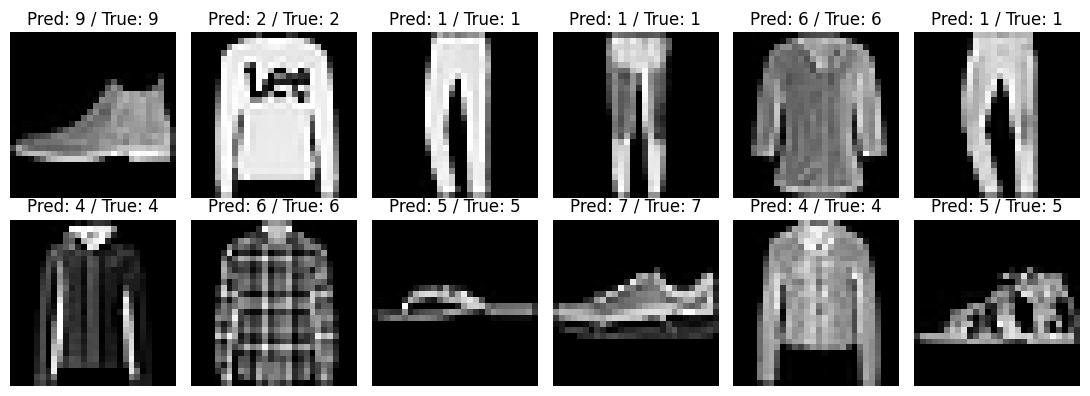

In [22]:
predictions = model.predict(
    X_test[:12]
).argmax(axis=1)

fig, axes = plt.subplots(
    2, 6,
    figsize=(11, 4)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        X_test[i, :, :, 0],
        cmap='gray'
    )

    ax.set_title(
        f'Pred: {predictions[i]} / True: {y_test[i]}'
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

This displays 12 test images alongside:
- Predicted category.

- Actual category.

If both labels match, the prediction is correct.

In [23]:
num_heads=4

In [24]:
## Compile and Train
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [25]:
## Train

history = model.fit(

    X_train[:100000],

    y_train[:100000],

    validation_split=0.1,

    epochs=5,

    batch_size=128

)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 16s 24ms/step - accuracy: 0.8861 - loss: 0.3116 - val_accuracy: 0.8792 - val_loss: 0.3318
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8864 - loss: 0.3074 - val_accuracy: 0.8833 - val_loss: 0.3261
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8899 - loss: 0.3001 - val_accuracy: 0.8863 - val_loss: 0.3105
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8908 - loss: 0.2972 - val_accuracy: 0.8875 - val_loss: 0.3143
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8933 - loss: 0.2865 - val_accuracy: 0.8783 - val_loss: 0.3321


In [26]:
## Evaluate
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8719 - loss: 0.3567


[0.35668596625328064, 0.8719000220298767]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


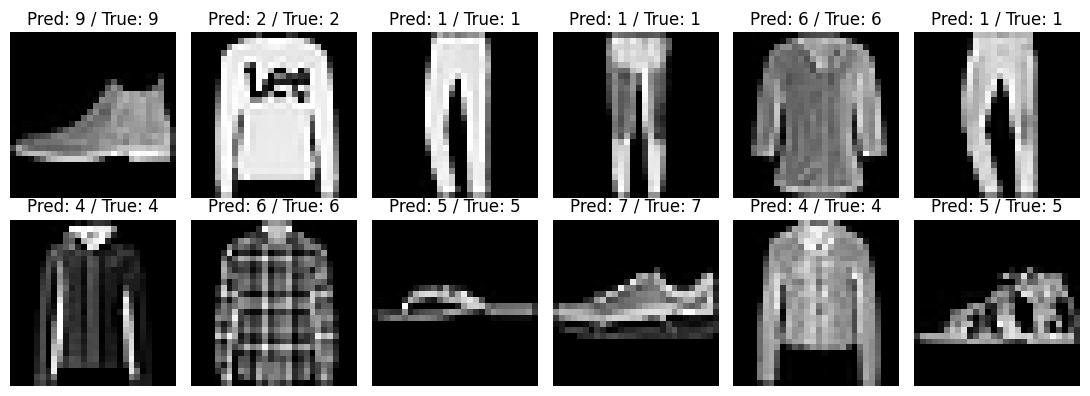

In [27]:
### Visualise predictions

predictions = model.predict(
    X_test[:12]
).argmax(axis=1)

fig, axes = plt.subplots(
    2, 6,
    figsize=(11, 4)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        X_test[i, :, :, 0],
        cmap='gray'
    )

    ax.set_title(
        f'Pred: {predictions[i]} / True: {y_test[i]}'
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

## Experiment with Transformer blocks
The original model uses one TransformerBlock.

In [29]:
PositionEmbedding(number_of_patches),

TransformerBlock(),

TransformerBlock(),

layers.GlobalAveragePooling1D(),

(<GlobalAveragePooling1D name=global_average_pooling1d_1, built=True>,)

More blocks increase model depth and parameter count, potentially improving representation learning but also increasing training requirements and overfitting risk.